# FinanceBench RAG — Notebook 02: Retrieval Experiments

**Where we are.** Notebook 01 gave the full-benchmark baseline (150 questions, 84 filings, 31,870 chunks of 256 words):

| Retriever | Recall@1 | Recall@3 | Recall@5 | Recall@10 | MRR |
|---|---|---|---|---|---|
| BM25 | 0.147 | 0.247 | 0.267 | 0.307 | 0.198 |
| Dense (bge-small) | 0.240 | 0.447 | 0.560 | 0.667 | 0.375 |

**Goal of this notebook:** find which retrieval choices raise that 56% Recall@5. Four experiments:

- **A. Retriever type:** BM25 vs dense vs hybrid vs hybrid + reranker
- **B. Chunk size:** 128 / 256 / 384 words
- **C. Page-header tagging:** prepend each page's opening line (e.g. "Consolidated Statement of Cash Flows") to every chunk on that page
- **D. Breakdown by question type:** which kinds of questions still fail

Still no LLM API needed. **Use a T4 GPU runtime** (Runtime → Change runtime type → T4 GPU).

## 0. Setup
Same as Notebook 01. The PDFs and the 256-word embeddings are already on your Drive, so this part is fast.

In [14]:
!pip -q install pymupdf rank_bm25 sentence-transformers faiss-cpu

In [15]:
import os, re, time, urllib.request
import numpy as np
import pandas as pd
import pymupdf
import faiss, torch
from tqdm.auto import tqdm
from rank_bm25 import BM25Okapi
from sentence_transformers import SentenceTransformer, CrossEncoder

from google.colab import drive
drive.mount('/content/drive')
ROOT = '/content/drive/MyDrive/financebench_rag'
PDF_DIR = f'{ROOT}/pdfs'
os.makedirs(PDF_DIR, exist_ok=True)
REPO = 'https://raw.githubusercontent.com/patronus-ai/financebench/main'

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', DEVICE)   # should say "cuda"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
device: cuda


In [16]:
qs = pd.read_json(f'{REPO}/data/financebench_open_source.jsonl', lines=True)
qs['gold_pages'] = qs['evidence'].apply(lambda ev: sorted({e['evidence_page_num'] for e in ev}))
doc_names = sorted(qs.doc_name.unique())

def get_pdf(name):
    path = f'{PDF_DIR}/{name}.pdf'
    if not os.path.exists(path):
        urllib.request.urlretrieve(f'{REPO}/pdfs/{name}.pdf', path)
    return path

pages = {}
for name in tqdm(doc_names):
    with pymupdf.open(get_pdf(name)) as pdf:
        pages[name] = [p.get_text() for p in pdf]
print(len(qs), 'questions |', len(doc_names), 'docs |', sum(len(v) for v in pages.values()), 'pages')

  0%|          | 0/84 [00:00<?, ?it/s]

150 questions | 84 docs | 12013 pages


## 1. Chunking, now with an optional page header

Same chunker as before, with one new option, `header_words`.

📘 **Concept: contextual chunk headers.** When a financial table is split into chunks, only the *first* chunk on the page contains the title ("Consolidated Statement of Cash Flows"). The rest are just rows of numbers, so nothing in them matches a question that says "cash flow statement". Prepending a short header (here, the page's first *N* words) to every chunk gives each chunk that missing context. It costs nothing at query time.

We keep two text fields:
- `text`: the raw chunk (what the LLM will read later)
- `embed_text`: header + chunk (what we search over)

With `header_words=0` they're identical, so the 256-word embeddings from Notebook 01 are reused from Drive.

In [17]:
def chunk_doc(name, page_texts, size=256, overlap=32, header_words=0):
    out = []
    step = size - overlap
    for pno, text in enumerate(page_texts):
        words = text.split()
        if not words:
            continue
        # skip the "Table of Contents" link that starts most 10-K pages
        hw = words[3:] if [w.lower() for w in words[:3]] == ['table', 'of', 'contents'] else words
        header = ' '.join(hw[:header_words]) if header_words else ''
        for start in range(0, max(len(words) - overlap, 1), step):
            piece = ' '.join(words[start:start + size])
            embed_text = f'{header} | {piece}' if (header and start > 0) else piece
            out.append({'doc_name': name, 'page': pno, 'text': piece, 'embed_text': embed_text})
    return out

def make_chunks(size=256, header_words=0):
    overlap = size // 8
    return pd.DataFrame([c for n in doc_names for c in chunk_doc(n, pages[n], size, overlap, header_words)])

# peek: what does a page's opening look like?
print(' '.join(pages['3M_2018_10K'][59].split()[:20]))

Table of Contents 3M Company and Subsidiaries Consolidated Statement of Cash Flow s Years ended December 31 (Millions) 2018 2017


## 2. Models

- **Embedder (bi-encoder):** `bge-small`, same as Notebook 01.
- **Reranker (cross-encoder):** `BAAI/bge-reranker-base`.

📘 **Concept: bi-encoder vs cross-encoder.**
- A **bi-encoder** (our embedder) encodes the question and each chunk *separately* into vectors, then compares them. It's fast, because chunk vectors are computed once and reused, but the question and chunk never "see" each other.
- A **cross-encoder** reads the question and a chunk *together* in one pass and outputs a relevance score. It's much more accurate, because it can match "capital expenditure" against "purchases of property, plant and equipment" in context, but it's too slow to run on all 380 chunks of a 10-K for every question.

So we use both: the fast retriever shortlists ~30 candidates, then the cross-encoder **reranks** that shortlist. This two-stage "retrieve then rerank" pattern is standard in production search.

In [18]:
embedder = SentenceTransformer('BAAI/bge-small-en-v1.5', device=DEVICE)
QUERY_PREFIX = 'Represent this sentence for searching relevant passages: '
reranker = CrossEncoder('BAAI/bge-reranker-base', max_length=512, device=DEVICE)

def tokenize(s):
    return re.findall(r'[a-z0-9]+', s.lower())

def embed_chunks(chunks, tag):
    # load from Drive if this exact setup was already embedded, otherwise embed and save
    cache = f'{ROOT}/chunk_vecs_{tag}.npy'
    if os.path.exists(cache) and len(np.load(cache)) == len(chunks):
        print(f'[{tag}] loaded cached embeddings')
        return np.load(cache)
    t0 = time.time()
    vecs = embedder.encode(chunks.embed_text.tolist(), batch_size=128, normalize_embeddings=True,
                           show_progress_bar=True).astype('float32')
    print(f'[{tag}] embedded {len(chunks)} chunks in {time.time()-t0:.0f}s')
    np.save(cache, vecs)
    return vecs

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

## 3. Retrievers

All four retrievers live in one class so every experiment uses identical code.

📘 **Concept: hybrid search with Reciprocal Rank Fusion (RRF).** BM25 is good at exact terms ("FY2018", "EBITDA"); dense search is good at meaning. Their *scores* aren't on the same scale, so we can't just add them. RRF combines their *ranks* instead:

$$\text{RRF}(d) = \sum_{r \in \{\text{BM25},\,\text{dense}\}} \frac{1}{c + \text{rank}_r(d)}, \qquad c = 60$$

A chunk ranked highly by *either* retriever gets a high fused score; a chunk ranked highly by *both* gets the highest. The constant $c$ dampens the gap between rank 1 and rank 2 so one retriever can't dominate.

In [19]:
class RAGIndex:
    def __init__(self, chunks, vecs):
        self.chunks = chunks
        self.by_doc = {}
        for name, grp in chunks.groupby('doc_name'):
            ids = grp.index.to_numpy()
            bm = BM25Okapi([tokenize(t) for t in grp.embed_text])
            ix = faiss.IndexFlatIP(vecs.shape[1])
            ix.add(vecs[ids])
            self.by_doc[name] = (bm, ix, ids)

    def bm25(self, q, doc, k):
        bm, _, ids = self.by_doc[doc]
        return ids[np.argsort(-bm.get_scores(tokenize(q)))[:k]]

    def dense(self, q, doc, k):
        _, ix, ids = self.by_doc[doc]
        qv = embedder.encode([QUERY_PREFIX + q], normalize_embeddings=True).astype('float32')
        _, top = ix.search(qv, min(k, len(ids)))
        return ids[top[0]]

    def hybrid(self, q, doc, k, pool=50, c=60):
        fused = {}
        for ranked in (self.bm25(q, doc, pool), self.dense(q, doc, pool)):
            for rank, i in enumerate(ranked):
                fused[i] = fused.get(i, 0) + 1 / (c + rank + 1)
        return np.array(sorted(fused, key=fused.get, reverse=True)[:k])

    def rerank(self, q, doc, k, pool=30):
        cand = self.hybrid(q, doc, pool)
        scores = reranker.predict([(q, self.chunks.at[i, 'embed_text']) for i in cand], batch_size=32)
        return cand[np.argsort(-scores)][:k]

## 4. Evaluation (same metrics as Notebook 01)

Recall@k = did any of the top-*k* chunks come from a gold page? MRR = how high was the first correct chunk ranked? Every run is appended to `all_results`, which we save to Drive for plots and the report.

In [20]:
KS = (1, 3, 5, 10)

def evaluate(index, method):
    fn = getattr(index, method)
    rows = []
    for _, q in qs.iterrows():
        got_pages = index.chunks.loc[fn(q.question, q.doc_name, k=max(KS)), 'page'].tolist()
        hits = [p in q.gold_pages for p in got_pages]
        first = next((i for i, h in enumerate(hits) if h), None)
        r = {f'recall@{k}': any(hits[:k]) for k in KS}
        r['MRR'] = 0 if first is None else 1 / (first + 1)
        r['question_type'] = q.question_type
        rows.append(r)
    return pd.DataFrame(rows)

all_results = []   # one row per (config, method)
per_question = {}  # raw per-question results, for breakdowns

def run(config, index, methods):
    for m in methods:
        t0 = time.time()
        res = evaluate(index, m)
        per_question[(config, m)] = res
        row = res.drop(columns='question_type').mean().to_dict()
        row.update(config=config, method=m, sec_per_query=(time.time() - t0) / len(qs))
        all_results.append(row)
    return show()

def show():
    df = pd.DataFrame(all_results)
    cols = ['config', 'method'] + [f'recall@{k}' for k in KS] + ['MRR', 'sec_per_query']
    return df[cols].round(3)

## Experiment A: retriever type (256-word chunks)

**Hypothesis:** hybrid beats either retriever alone (BM25 catches exact terms like "FY2018" that dense misses), and the reranker adds the most, because it reads question and chunk together.

In [21]:
chunks_256 = make_chunks(256)
vecs_256 = embed_chunks(chunks_256, '256_full')   # reuses Notebook 01's file
idx_256 = RAGIndex(chunks_256, vecs_256)
run('256 words', idx_256, ['bm25', 'dense', 'hybrid', 'rerank'])

[256_full] loaded cached embeddings


,config,method,recall@1,recall@3,recall@5,recall@10,MRR,sec_per_query
0,256 words,bm25,0.147,0.247,0.267,0.307,0.198,0.011
1,256 words,dense,0.240,0.447,0.560,0.667,0.375,0.055
2,256 words,hybrid,0.160,0.260,0.333,0.427,0.231,0.016
3,256 words,rerank,0.200,0.393,0.507,0.667,0.332,0.940


## Experiment B: chunk size

📘 **Concept: max sequence length (truncation).** Embedding models have a hard input limit. For `bge-small` it's **512 tokens**; anything past that is silently cut off and never embedded. Financial tables are token-hungry: a number like `1,577` becomes several tokens. So a 256-*word* chunk of a table can exceed 512 *tokens*. Let's measure how often that happens before comparing sizes, because truncation could be a hidden reason table questions fail.

In [22]:
def truncation_report(chunks, n=3000):
    sample = chunks.embed_text.sample(min(n, len(chunks)), random_state=0).tolist()
    lens = np.array([len(x) for x in embedder.tokenizer(sample)['input_ids']])
    return {'median tokens': int(np.median(lens)), '% over 512 (truncated)': round(100 * (lens > 512).mean(), 1)}

chunk_sets = {256: chunks_256}
for size in (128, 384):
    chunk_sets[size] = make_chunks(size)
pd.DataFrame({f'{s} words': {'chunks': len(c), **truncation_report(c)} for s, c in sorted(chunk_sets.items())})

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (1020 > 512). Running this sequence through the model will result in indexing errors


,128 words,256 words,384 words
chunks,59223.0,31870.0,22703.0
median tokens,161.0,315.0,453.0
% over 512 (truncated),0.1,1.8,17.9


In [23]:
# ~5 min of GPU embedding per size
for size in (128, 384):
    vecs = embed_chunks(chunk_sets[size], f'{size}_full')
    idx = RAGIndex(chunk_sets[size], vecs)
    run(f'{size} words', idx, ['dense', 'rerank'])
show()

[128_full] loaded cached embeddings
[384_full] loaded cached embeddings


,config,method,recall@1,recall@3,recall@5,recall@10,MRR,sec_per_query
0,256 words,bm25,0.147,0.247,0.267,0.307,0.198,0.011
1,256 words,dense,0.240,0.447,0.560,0.667,0.375,0.055
2,256 words,hybrid,0.160,0.260,0.333,0.427,0.231,0.016
3,256 words,rerank,0.200,0.393,0.507,0.667,0.332,0.940
4,128 words,dense,0.300,0.460,0.513,0.640,0.399,0.013
5,128 words,rerank,0.173,0.353,0.460,0.587,0.291,0.610
6,384 words,dense,0.240,0.440,0.527,0.660,0.366,0.013
7,384 words,rerank,0.207,0.360,0.480,0.640,0.324,0.998


## Experiment C: page-header tagging

**Hypothesis:** the 3M capex miss happened because the chunk holding "Purchases of property, plant and equipment … 1,577" didn't contain the words "cash flow statement". Prepending the page's first 20 words (which include the statement title) to every chunk should fix this class of miss, especially for `metrics-generated` questions, which all ask about a specific financial statement.

In [24]:
HEADER_WORDS = 20
chunks_hdr = make_chunks(256, header_words=HEADER_WORDS)
print(chunks_hdr.embed_text.iloc[200][:300], '...\n')
vecs_hdr = embed_chunks(chunks_hdr, f'256_hdr{HEADER_WORDS}_full')
idx_hdr = RAGIndex(chunks_hdr, vecs_hdr)
run('256 words + header', idx_hdr, ['bm25', 'dense', 'hybrid', 'rerank'])

in fair value (including the amount attributable to ineffectiveness) will be recorded within other comprehensive income and reclassified to earnings | does not grant share-based payments to nonemployees or customers, this ASU will not have a material impact on its consolidated results of operations  ...

[256_hdr20_full] loaded cached embeddings


,config,method,recall@1,recall@3,recall@5,recall@10,MRR,sec_per_query
0,256 words,bm25,0.147,0.247,0.267,0.307,0.198,0.011
1,256 words,dense,0.240,0.447,0.560,0.667,0.375,0.055
2,256 words,hybrid,0.160,0.260,0.333,0.427,0.231,0.016
3,256 words,rerank,0.200,0.393,0.507,0.667,0.332,0.940
4,128 words,dense,0.300,0.460,0.513,0.640,0.399,0.013
5,128 words,rerank,0.173,0.353,0.460,0.587,0.291,0.610
6,384 words,dense,0.240,0.440,0.527,0.660,0.366,0.013
7,384 words,rerank,0.207,0.360,0.480,0.640,0.324,0.998
8,256 words + header,bm25,0.167,0.240,0.260,0.313,0.212,0.004
9,256 words + header,dense,0.293,0.480,0.533,0.653,0.399,0.013


## Experiment D: which question types still fail?

FinanceBench has three question types (50 each):
- `metrics-generated`: pull or compute a number from a financial statement
- `domain-relevant`: analyst-style questions (e.g. "Is 3M capital-intensive?")
- `novel-generated`: free-form questions written about the filing

In [25]:
rows = {}
for (config, m), res in per_question.items():
    if m in ('dense', 'rerank'):
        rows[f'{config} | {m}'] = res.groupby('question_type')['recall@5'].mean()
pd.DataFrame(rows).T.round(2)

question_type,domain-relevant,metrics-generated,novel-generated
256 words | dense,0.36,0.80,0.52
256 words | rerank,0.30,0.64,0.58
128 words | dense,0.28,0.70,0.56
128 words | rerank,0.26,0.60,0.52
384 words | dense,0.30,0.80,0.48
384 words | rerank,0.24,0.62,0.58
256 words + header | dense,0.32,0.76,0.52
256 words + header | rerank,0.26,0.64,0.58


## 5. Save results and plot

saved to Drive: retrieval_results.csv


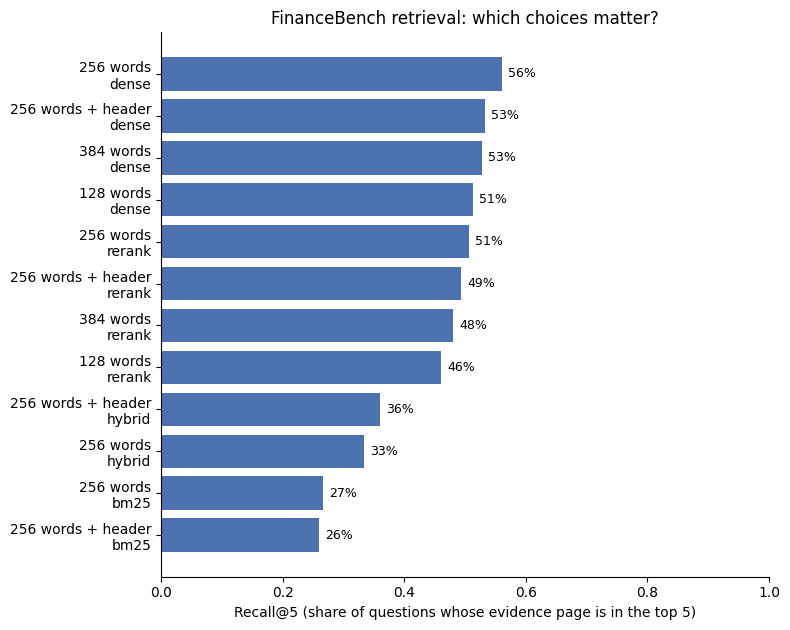

In [26]:
import matplotlib.pyplot as plt

results_df = show()
results_df.to_csv(f'{ROOT}/retrieval_results.csv', index=False)
print('saved to Drive: retrieval_results.csv')

plot_df = results_df.assign(label=results_df.config + '\n' + results_df.method).sort_values('recall@5')
fig, ax = plt.subplots(figsize=(8, 0.45 * len(plot_df) + 1))
ax.barh(plot_df.label, plot_df['recall@5'], color='#4C72B0')
for y, v in enumerate(plot_df['recall@5']):
    ax.text(v + 0.01, y, f'{v:.0%}', va='center', fontsize=9)
ax.set_xlim(0, 1)
ax.set_xlabel('Recall@5 (share of questions whose evidence page is in the top 5)')
ax.set_title('FinanceBench retrieval: which choices matter?')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig(f'{ROOT}/recall_at5.png', dpi=200)
plt.show()

## What to send back
1. The final results table (section 5)
2. The truncation table (Experiment B)
3. The question-type breakdown (Experiment D)

Notebook 03 will take the best retriever from here, add the LLM to generate answers, and score answer accuracy.